Total Samples: 150
Training Samples: 112
Validation Samples: 38


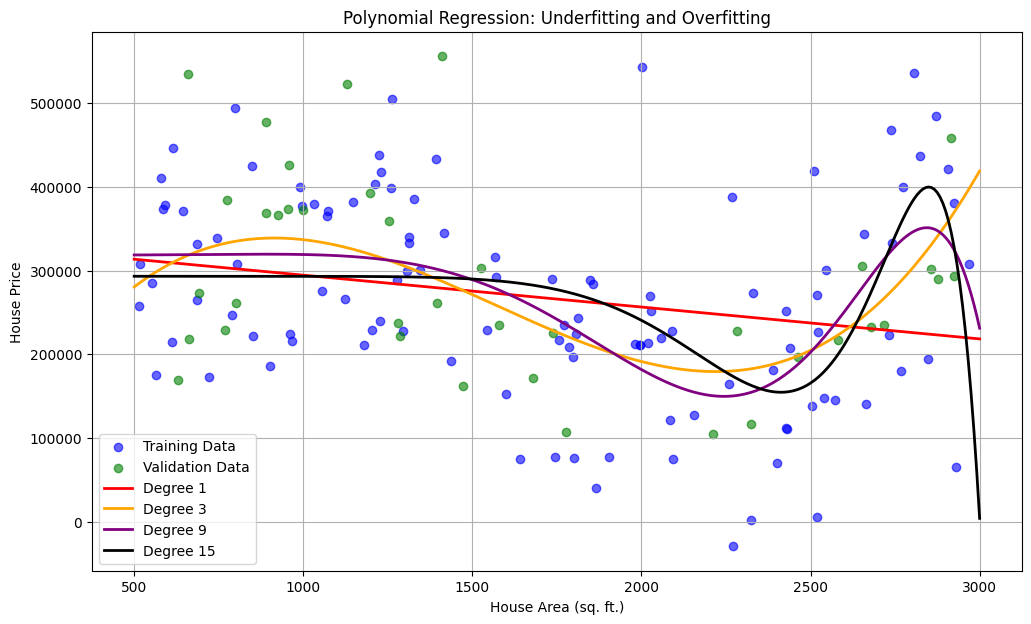

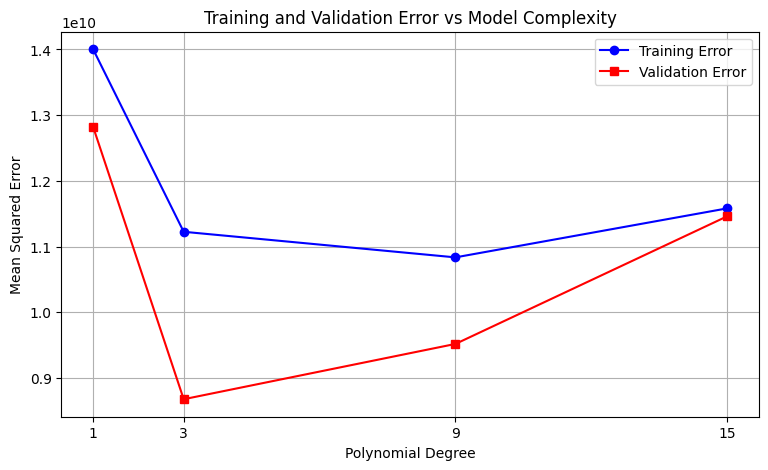


Error Comparison:
Degree 1: Training MSE = 14003221955.78, Validation MSE = 12822837870.56
Degree 3: Training MSE = 11226103307.70, Validation MSE = 8678839265.00
Degree 9: Training MSE = 10836694702.13, Validation MSE = 9519962711.08
Degree 15: Training MSE = 11582279481.67, Validation MSE = 11461755420.44

Bias-Variance Analysis:

Degree: 1
Bias^2: 5184682949.52
Variance: 171248233.06

Degree: 3
Bias^2: 70728446.45
Variance: 280503090.18

Degree: 9
Bias^2: 247480258.97
Variance: 384947679.70

Degree: 15
Bias^2: 2558018696.79
Variance: 501551871.57


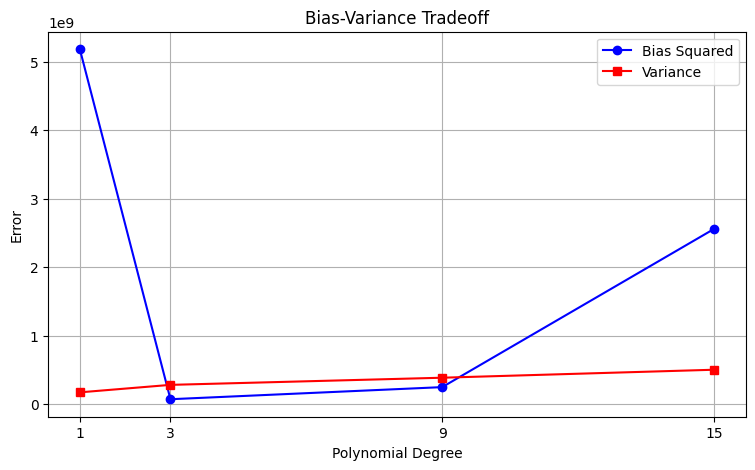


Best Polynomial Degree: 3
Minimum Validation MSE: 8678839265.0
Corresponding Training MSE: 11226103307.7

Model Selection Completed.


In [6]:

# Experiment 5: Bias-Variance, Overfitting and Underfitting Analysis

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# ------------------------------------------------
# TASK 1: Generate House Price Dataset
# ------------------------------------------------

np.random.seed(42)

# Generate 150 house area samples
X = np.sort(np.random.uniform(500, 3000, 150)).reshape(-1, 1)

# Hidden nonlinear relationship
y = (
    50000
    + 100 * X.flatten()
    + 0.015 * X.flatten()**2
    + 200000 * np.sin(X.flatten() / 500)
    + np.random.normal(0, 100000, 150)
)

y = y.reshape(-1, 1)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Total Samples:", len(X))
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))


# ------------------------------------------------
# TASK 2: Fit Polynomial Regression Models
# ------------------------------------------------

degrees = [1, 3, 9, 15]

models = {}
train_errors = []
validation_errors = []

X_plot = np.linspace(500, 3000, 300).reshape(-1, 1)

plt.figure(figsize=(12, 7))

plt.scatter(
    X_train, y_train,
    color='blue',
    label='Training Data',
    alpha=0.6
)

plt.scatter(
    X_val, y_val,
    color='green',
    label='Validation Data',
    alpha=0.6
)

colors = ['red', 'orange', 'purple', 'black']

for degree, color in zip(degrees, colors):

    # Create polynomial regression model
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    # Train model
    model.fit(X_train, y_train)

    models[degree] = model

    # Predictions
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_errors.append(train_mse)
    validation_errors.append(val_mse)

    # Plot fitted curve
    y_plot = model.predict(X_plot)

    plt.plot(
        X_plot,
        y_plot,
        color=color,
        linewidth=2,
        label=f'Degree {degree}'
    )

plt.title("Polynomial Regression: Underfitting and Overfitting")
plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------
# TASK 3: Training and Validation Error
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    degrees,
    train_errors,
    marker='o',
    color='blue',
    label='Training Error'
)

plt.plot(
    degrees,
    validation_errors,
    marker='s',
    color='red',
    label='Validation Error'
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")

plt.title("Training and Validation Error vs Model Complexity")

plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

print("\nError Comparison:")

for i, degree in enumerate(degrees):
    print(
        f"Degree {degree}: "
        f"Training MSE = {train_errors[i]:.2f}, "
        f"Validation MSE = {validation_errors[i]:.2f}"
    )


# ------------------------------------------------
# TASK 4: Estimate Bias^2 and Variance
# Through Repeated Resampling
# ------------------------------------------------

degrees_bias_variance = [1, 3, 9, 15]

n_repeats = 50

# Fixed evaluation points
X_test = np.linspace(500, 3000, 100).reshape(-1, 1)

# True underlying function without noise
def true_function(x):
    return (
        50000
        + 100 * x.flatten()
        + 0.015 * x.flatten()**2
        + 200000 * np.sin(x.flatten() / 500)
    )

y_true = true_function(X_test)

bias_squared = []
variance_values = []

for degree in degrees_bias_variance:

    predictions = []

    for repeat in range(n_repeats):

        # Generate a new resampled dataset
        X_sample = np.random.uniform(
            500, 3000, 150
        ).reshape(-1, 1)

        y_sample = true_function(X_sample) + np.random.normal(
            0, 100000, 150
        )

        # Train polynomial model
        model = make_pipeline(
            PolynomialFeatures(degree=degree),
            LinearRegression()
        )

        model.fit(X_sample, y_sample)

        # Predict on fixed test points
        prediction = model.predict(X_test)

        predictions.append(prediction.flatten())

    predictions = np.array(predictions)

    # Average predictions
    mean_prediction = np.mean(predictions, axis=0)

    # Calculate squared bias
    bias = np.mean(
        (mean_prediction - y_true)**2
    )

    # Calculate variance
    variance = np.mean(
        np.var(predictions, axis=0)
    )

    bias_squared.append(bias)
    variance_values.append(variance)

print("\nBias-Variance Analysis:")

for i, degree in enumerate(degrees_bias_variance):
    print(f"\nDegree: {degree}")
    print(f"Bias^2: {bias_squared[i]:.2f}")
    print(f"Variance: {variance_values[i]:.2f}")


# Plot Bias^2 and Variance
plt.figure(figsize=(9, 5))

plt.plot(
    degrees_bias_variance,
    bias_squared,
    marker='o',
    label='Bias Squared',
    color='blue'
)

plt.plot(
    degrees_bias_variance,
    variance_values,
    marker='s',
    label='Variance',
    color='red'
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Error")

plt.title("Bias-Variance Tradeoff")

plt.xticks(degrees_bias_variance)
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------
# TASK 5: Select Best Polynomial Degree
# ------------------------------------------------

best_index = np.argmin(validation_errors)
best_degree = degrees[best_index]

print("\nBest Polynomial Degree:", best_degree)

print("Minimum Validation MSE:",
      round(validation_errors[best_index], 2))

print("Corresponding Training MSE:",
      round(train_errors[best_index], 2))

print("\nModel Selection Completed.")
